In [1]:
!pip install tensorflow pandas numpy matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint

In [3]:
metadata = pd.read_csv("HAM10000_metadata.csv")
metadata = metadata[metadata['dx'].isin(['nv', 'mel'])]
metadata['label'] = metadata['dx'].map({'nv': 0, 'mel': 1})

In [10]:
image_dir = "HAM10000_images_merged"
image_size = 224
images, labels = [], []
for _, row in metadata.iterrows():
    img_path = os.path.join(image_dir, row['image_id'] + ".jpg")
    if os.path.exists(img_path):
        img = load_img(img_path, target_size=(image_size, image_size))
        img = img_to_array(img) / 255.0
        images.append(img)
        labels.append(row['label'])
X = np.array(images)
y = to_categorical(np.array(labels), num_classes=2)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model.layers:
    layer.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
output = Dense(2, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

In [7]:
checkpoint = ModelCheckpoint("melanoma_model.h5", monitor='val_accuracy', save_best_only=True)
history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
                    epochs=10, batch_size=32, callbacks=[checkpoint])

Epoch 1/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8180 - loss: 0.4460

97/97 ━━━━━━━━━━━━━━━━━━━━ 176s 2s/step - accuracy: 0.8185 - loss: 0.4455 - val_accuracy: 0.8669 - val_loss: 0.3993
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.8943 - loss: 0.3515 - val_accuracy: 0.8669 - val_loss: 0.3960
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.8910 - loss: 0.3577 - val_accuracy: 0.8669 - val_loss: 0.3932
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.8987 - loss: 0.3325 - val_accuracy: 0.8669 - val_loss: 0.3956
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.8905 - loss: 0.3534 - val_accuracy: 0.8669 - val_loss: 0.3913
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.8959 - loss: 0.3390 - val_accuracy: 0.8669 - val_loss: 0.3885
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 161s 2s/step - accuracy: 0.8876 - loss: 0.3517 - val_accuracy: 0.8669 - val_loss: 0.3865
Epoch 8/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step - accuracy: 0.8968 - loss: 0.3388 - val_accuracy: 0.8669 - val_loss: 0.

In [8]:
model.save("melanoma_model.h5")  


In [9]:
import os
import zipfile
import shutil

# Existing unzipped folder
unzipped_folder = "HAM10000_images"

# The ZIP file
zip_file = "HAM10000_images_part_2.zip"

# Destination merged folder
merged_folder = "HAM10000_images_merged"
os.makedirs(merged_folder, exist_ok=True)

# Step 1: Copy files from unzipped folder
for filename in os.listdir(unzipped_folder):
    src = os.path.join(unzipped_folder, filename)
    dst = os.path.join(merged_folder, filename)
    if not os.path.exists(dst):
        shutil.copy2(src, dst)

print("✅ Copied from unzipped folder.")

# Step 2: Extract files from ZIP into merged folder
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(merged_folder)

print("✅ Extracted from ZIP file.")

# Step 3: Summary
print(f"✅ All images merged into: {merged_folder}")


✅ Copied from unzipped folder.
✅ Extracted from ZIP file.
✅ All images merged into: HAM10000_images_merged


In [3]:
import os

problem_file = "balanced_dataset/train/melanoma/ISIC_0029885.jpg"

try:
    os.remove(problem_file)
    print(f"✅ Deleted locked file: {problem_file}")
except Exception as e:
    print(f"❌ Failed to delete: {e}")


✅ Deleted locked file: balanced_dataset/train/melanoma/ISIC_0029885.jpg


In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    "balanced_dataset/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

val_data = train_datagen.flow_from_directory(
    "balanced_dataset/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)


Found 1424 images belonging to 2 classes.
Found 355 images belonging to 2 classes.


In [7]:
history = model.fit(train_data, epochs=10, validation_data=val_data, callbacks=[checkpoint])


Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.7463 - loss: 1.0555

45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 542ms/step - accuracy: 0.7462 - loss: 1.0543 - val_accuracy: 0.5296 - val_loss: 0.6067
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 526ms/step - accuracy: 0.7773 - loss: 0.6495 - val_accuracy: 0.5070 - val_loss: 0.7393
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.8162 - loss: 0.4816

45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 551ms/step - accuracy: 0.8158 - loss: 0.4828 - val_accuracy: 0.5465 - val_loss: 0.7243
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 551ms/step - accuracy: 0.7754 - loss: 0.7645 - val_accuracy: 0.5014 - val_loss: 0.7891
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 544ms/step - accuracy: 0.8028 - loss: 0.5103 - val_accuracy: 0.5465 - val_loss: 0.7112
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 556ms/step - accuracy: 0.8343 - loss: 0.4595 - val_accuracy: 0.5352 - val_loss: 1.2439
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 557ms/step - accuracy: 0.8150 - loss: 0.3795 - val_accuracy: 0.5352 - val_loss: 1.4071
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8048 - loss: 0.4496

45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 563ms/step - accuracy: 0.8051 - loss: 0.4498 - val_accuracy: 0.7127 - val_loss: 0.5970
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.8346 - loss: 0.5426

45/45 ━━━━━━━━━━━━━━━━━━━━ 26s 573ms/step - accuracy: 0.8343 - loss: 0.5434 - val_accuracy: 0.7296 - val_loss: 0.5385
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.8300 - loss: 0.4161

45/45 ━━━━━━━━━━━━━━━━━━━━ 28s 613ms/step - accuracy: 0.8300 - loss: 0.4164 - val_accuracy: 0.7549 - val_loss: 0.6454


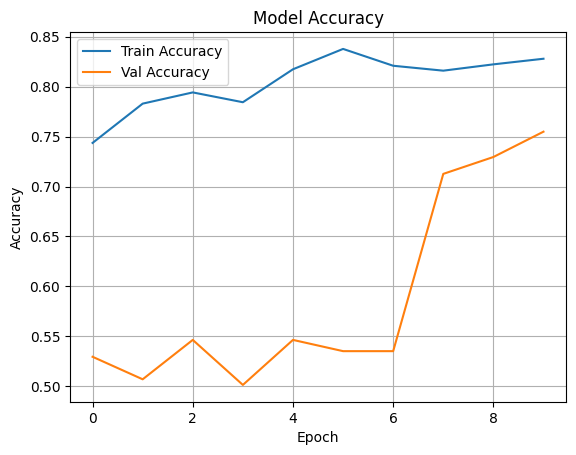

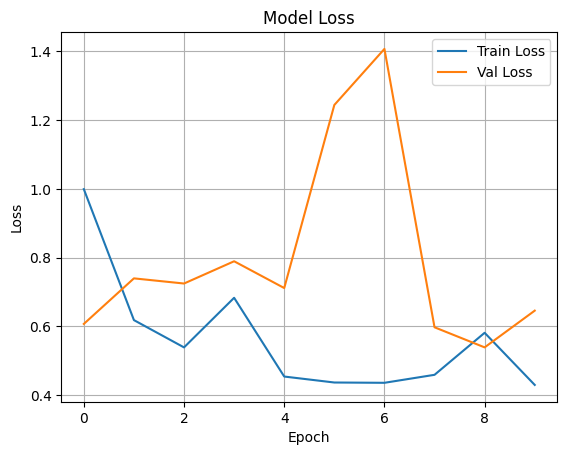

In [8]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()


In [10]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    "balanced_dataset",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

model.evaluate(test_data)


Found 2225 images belonging to 2 classes.
70/70 ━━━━━━━━━━━━━━━━━━━━ 18s 253ms/step - accuracy: 0.5637 - loss: 2.0974


[2.279639720916748, 0.5631460547447205]

In [11]:
checkpoint = ModelCheckpoint("melanoma_model.h5", save_best_only=True, monitor='val_accuracy', mode='max')
